# Taller — Deep Learning: ¿quién es esta persona?

## Presentado por: Johel Santiago Arias Becerra

**Machine Learning · Universidad Libre · Gustavo Santos** · Trabajo en parejas · 30 min + 5 min de socialización

Dataset: **Olivetti Faces** (400 fotos 64×64, 40 personas × 10 fotos).
Van a comparar **tres modelos del curso sobre el mismo problema de imágenes, con la misma partición**:

| # | Modelo | Conexión con la clase |
|---|---|---|
| 1 | Red densa (MLPClassifier) | La red que entrenamos con `load_digits` |
| 2 | SVM con kernel RBF + PCA | Parte A de hoy |
| 3 | Red convolucional (CNN, Keras) | La demo de rostros |

**Entregable:** este notebook ejecutado + la tabla comparativa (punto 4) + el párrafo de reflexión (punto 5).
Las celdas marcadas con `# TODO` son las que ustedes deben completar.

Copia de trabajo (la plantilla `02_Taller_DL_Rostros_ESTUDIANTES.ipynb` no se modifica).
Puntos 1–5 = enunciado oficial. Punto 6 = extra: reconocer fotos propias (`Yo`, etiqueta 40).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)   # reproducibilidad (numpy + python + TF)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Datos y partición (ya resuelto — no modificar)
Todos los modelos usan exactamente la misma partición: la comparación es justa.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Shape imágenes: (400, 64, 64)
Personas (clases): 40
Imágenes por persona: [10 10 10 10 10] ...
Rango de píxeles: 0.0 - 1.0


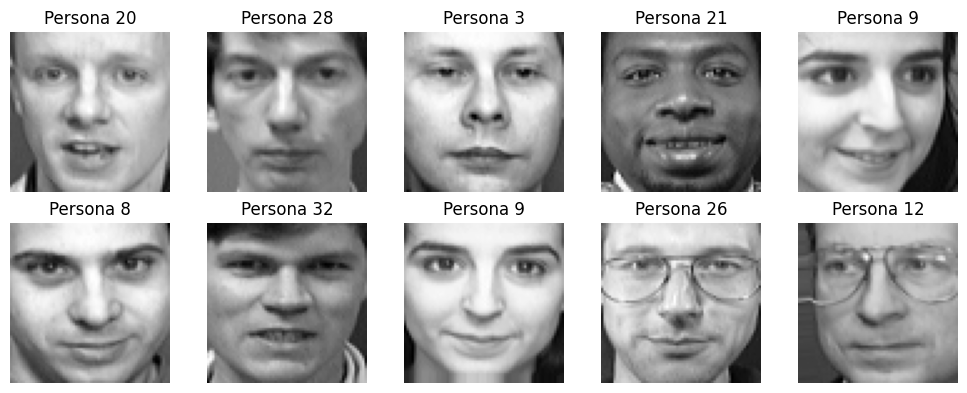

In [2]:
faces = fetch_olivetti_faces(shuffle=True, random_state=42)
images, y = faces.images, faces.target
print("Shape imágenes:", images.shape)            # (400, 64, 64)
print("Personas (clases):", len(np.unique(y)))    # 40
print("Imágenes por persona:", np.bincount(y)[:5], "...")   # 10 c/u
print("Rango de píxeles:", images.min(), "-", images.max())  # ya vienen en [0, 1]

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(f"Persona {y[i]}")
    plt.axis("off")
plt.tight_layout(); plt.show()

In [3]:
# Tensor de rango 4 para la CNN: (n_imágenes, alto, ancho, canales)
X = images[..., np.newaxis]          # (400, 64, 64, 1)

# 1) Separamos PRUEBA (20%) — no se toca hasta el final
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

# 2) Del resto separamos VALIDACIÓN (20%) para monitorear el entrenamiento
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=42)

print("Entrenamiento:", X_train.shape, "| Validación:", X_val.shape, "| Prueba:", X_test.shape)
# stratify=y garantiza 2 fotos de cada una de las 40 personas en prueba

# Versión "aplanada" para los modelos de sklearn: cada foto = vector de 64×64 = 4096 píxeles
Xtr_flat  = X_train.reshape(len(X_train), -1)
Xval_flat = X_val.reshape(len(X_val), -1)
Xte_flat  = X_test.reshape(len(X_test), -1)
print("Aplanado:", Xtr_flat.shape)

Entrenamiento: (256, 64, 64, 1) | Validación: (64, 64, 64, 1) | Prueba: (80, 64, 64, 1)
Aplanado: (256, 4096)


In [4]:
def graficar_historia(history, titulo=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history.history["accuracy"], label="entrenamiento")
    ax[0].plot(history.history["val_accuracy"], label="validación")
    ax[0].set_title(f"Accuracy {titulo}"); ax[0].set_xlabel("Época"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="entrenamiento")
    ax[1].plot(history.history["val_loss"], label="validación")
    ax[1].set_title(f"Pérdida (cross-entropy) {titulo}"); ax[1].set_xlabel("Época"); ax[1].legend()
    plt.tight_layout(); plt.show()

In [5]:
resultados = {}   # aquí guardaremos la accuracy en PRUEBA de cada modelo

## 1. Línea base: red densa (MLP) — ~5 min
Entrenen un `MLPClassifier` sobre las fotos aplanadas, igual que con `load_digits`.
- Escalen con `StandardScaler` (ajustado **solo** con entrenamiento).
- Prueben una arquitectura, por ejemplo `hidden_layer_sizes=(256,)`, `max_iter=500`, `random_state=42`.
- Reporten accuracy en prueba y guárdenla en `resultados["MLP"]`.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

# El scaler se ajusta SOLO con entrenamiento: si usáramos prueba,
# filtraríamos información que el modelo no debería haber visto.
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr_flat)
Xte_s = scaler.transform(Xte_flat)  # transform, no fit

mlp = MLPClassifier(hidden_layer_sizes=(256,), max_iter=500, random_state=42)
mlp.fit(Xtr_s, y_train)

pred_mlp = mlp.predict(Xte_s)
acc_mlp = accuracy_score(y_test, pred_mlp)
resultados["MLP"] = acc_mlp
print(f"MLP — accuracy en prueba: {acc_mlp:.3f}")

MLP — accuracy en prueba: 0.912


## 2. SVM + PCA ("eigenfaces") — ~8 min
4096 variables para 256 fotos es mucho. Primero reducimos dimensión con **PCA** (por ejemplo a 100 componentes) y luego aplicamos **SVM con kernel RBF**.
- Armen un `Pipeline` con `StandardScaler` → `PCA(n_components=100, whiten=True, random_state=42)` → `SVC(kernel="rbf")`.
- Hagan un `GridSearchCV` (cv=3) sobre al menos 2 valores de `C` y 2 de `gamma`.
- Reporten el mejor par (C, gamma) y la accuracy en prueba → `resultados["SVM + PCA"]`.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# 4096 vars y 256 fotos: PCA a 100 eigenfaces. whiten=True iguala la
# varianza de cada componente para que el RBF no lo domine el primer eje.
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=100, whiten=True, random_state=42)),
    ("svm", SVC(kernel="rbf")),
])

param_grid = {
    "svm__C": [1, 10],
    "svm__gamma": ["scale", 0.01],
}

# GridSearch usa train+val (X_temp): el CV interno hace las particiones.
Xtemp_flat = X_temp.reshape(len(X_temp), -1)
grid = GridSearchCV(pipe, param_grid, cv=3)
grid.fit(Xtemp_flat, y_temp)

print("Mejores parámetros:", grid.best_params_)
pred_svm = grid.predict(Xte_flat)
acc_svm = accuracy_score(y_test, pred_svm)
resultados["SVM + PCA"] = acc_svm
print(f"SVM + PCA — accuracy en prueba: {acc_svm:.3f}")

Mejores parámetros: {'svm__C': 10, 'svm__gamma': 'scale'}
SVM + PCA — accuracy en prueba: 0.988


## 3. CNN: mejorar la red de la demo — ~12 min
Partan de la CNN de la demo y hagan **al menos UNO** de estos cambios. Comparen las curvas contra las de la demo.
- **(a)** *Data augmentation*: agregar al inicio `keras.layers.RandomFlip("horizontal")`, `RandomRotation(0.05)`, `RandomZoom(0.1)`.
- **(b)** Cambiar la arquitectura: un tercer bloque `Conv2D + MaxPooling2D`, o más/menos filtros.
- **(c)** Cambiar la regularización: otro valor de `Dropout`, o quitarlo y ver qué pasa.

Usen `EarlyStopping` y evalúen **una sola vez** en prueba → `resultados["CNN"]`.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,629,736 (6.22 MB)

 Trainable params: 1,629,736 (6.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.0195 - loss: 3.7757 - val_accuracy: 0.0156 - val_loss: 3.6975
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0469 - loss: 3.6928 - val_accuracy: 0.0156 - val_loss: 3.6894
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0273 - loss: 3.6888 - val_accuracy: 0.0156 - val_loss: 3.6884
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0352 - loss: 3.6886 - val_accuracy: 0.0312 - val_loss: 3.6869
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0234 - loss: 3.6880 - val_accuracy: 0.0156 - val_loss: 3.6856
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0234 - loss: 3.6863 - val_accuracy: 0.0156 - val_loss: 3.6832
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0352 - loss: 3.6756 - val_accuracy: 0.0156 - val_loss: 3.6808
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0234 - loss: 3.6801 - val_accuracy: 0.0312 - val_loss:

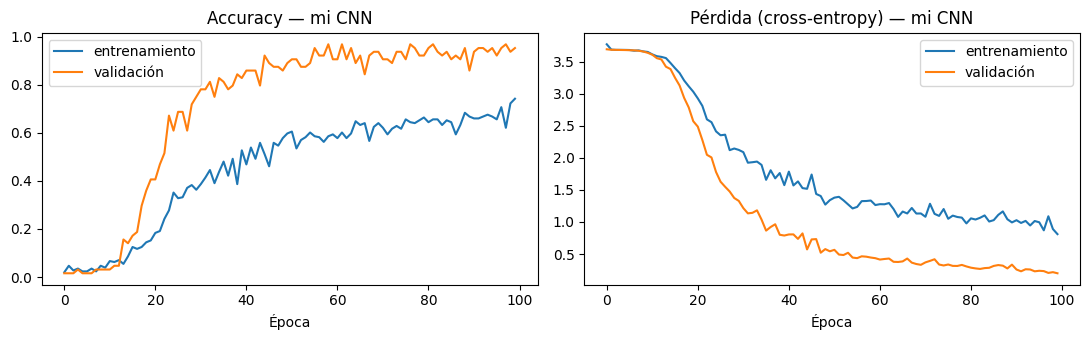

In [8]:
model = keras.Sequential([
    keras.Input(shape=(64, 64, 1)),
    # (a) data augmentation: más variedad con solo 256 fotos
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.1),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(40, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

early = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, start_from_epoch=15, restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    callbacks=[early],
)

# Si accuracy train >> val y val_loss sube, hay sobreajuste.
graficar_historia(history, "— mi CNN")

In [9]:
# Una sola evaluación en prueba (el enunciado lo pide explícitamente).
_, acc_cnn = model.evaluate(X_test, y_test, verbose=0)
resultados["CNN"] = float(acc_cnn)
pred_cnn = model.predict(X_test, verbose=0).argmax(axis=1)
print(f"CNN — accuracy en prueba: {acc_cnn:.3f}")
print("Cambio(s) realizado(s): data augmentation (flip horizontal, rotación 0.05, zoom 0.1)")

CNN — accuracy en prueba: 0.925
Cambio(s) realizado(s): data augmentation (flip horizontal, rotación 0.05, zoom 0.1)


## 4. Tabla comparativa

In [10]:
import pandas as pd
tabla = pd.DataFrame({"Accuracy (prueba)": resultados}).sort_values("Accuracy (prueba)", ascending=False)
tabla["Errores (de 80)"] = ((1 - tabla["Accuracy (prueba)"]) * len(y_test)).round().astype(int)
tabla

,Accuracy (prueba),Errores (de 80)
SVM + PCA,0.9875,1
CNN,0.9250,6
MLP,0.9125,7


## 4b. ¿Dónde se equivoca cada modelo?
Matriz de confusión (real vs predicho) y ejemplos de prueba. Los títulos en rojo son errores: `real → predicho`.

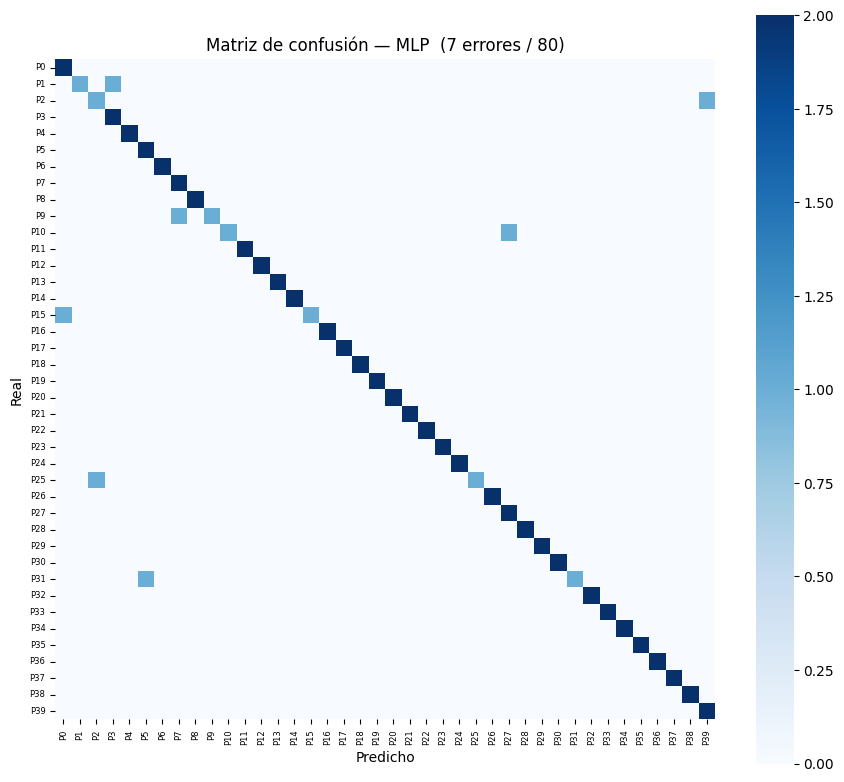

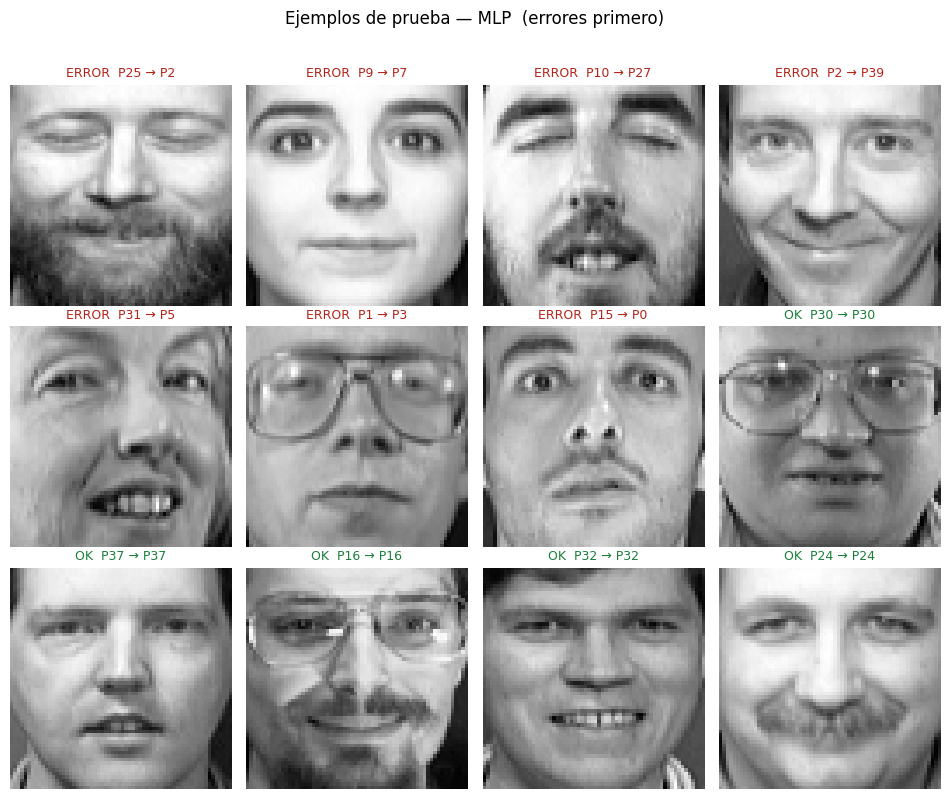

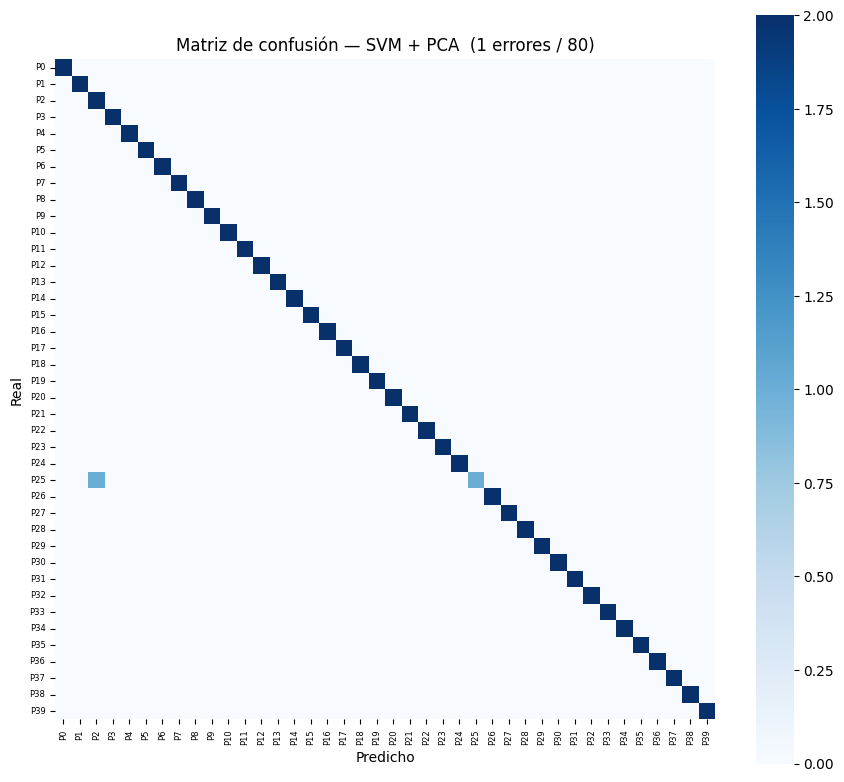

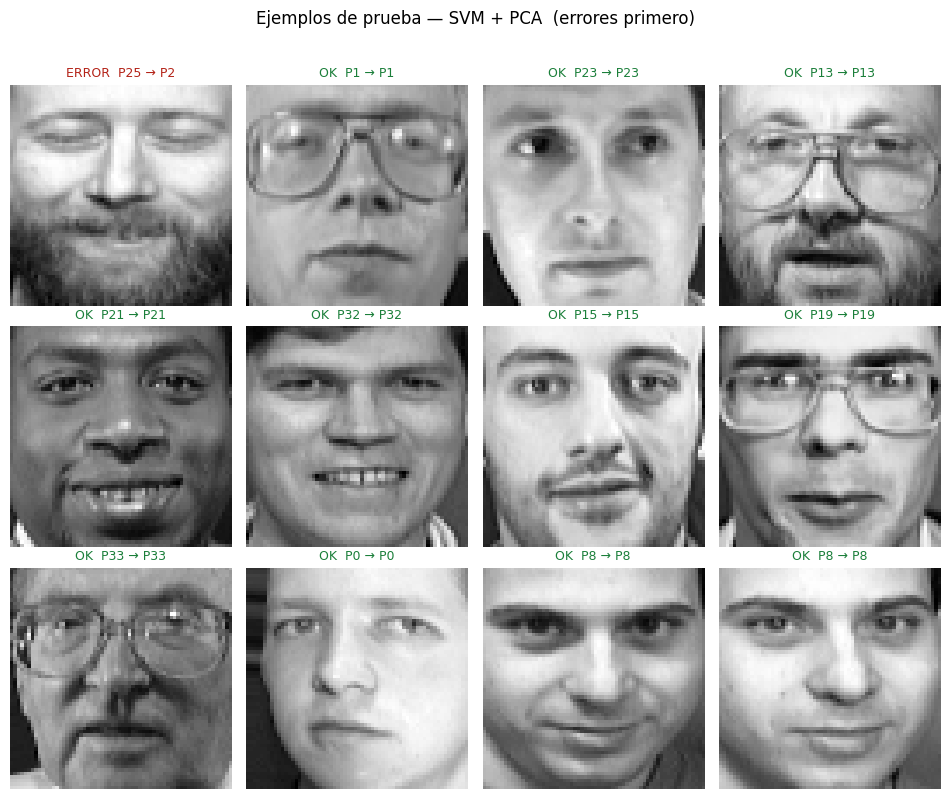

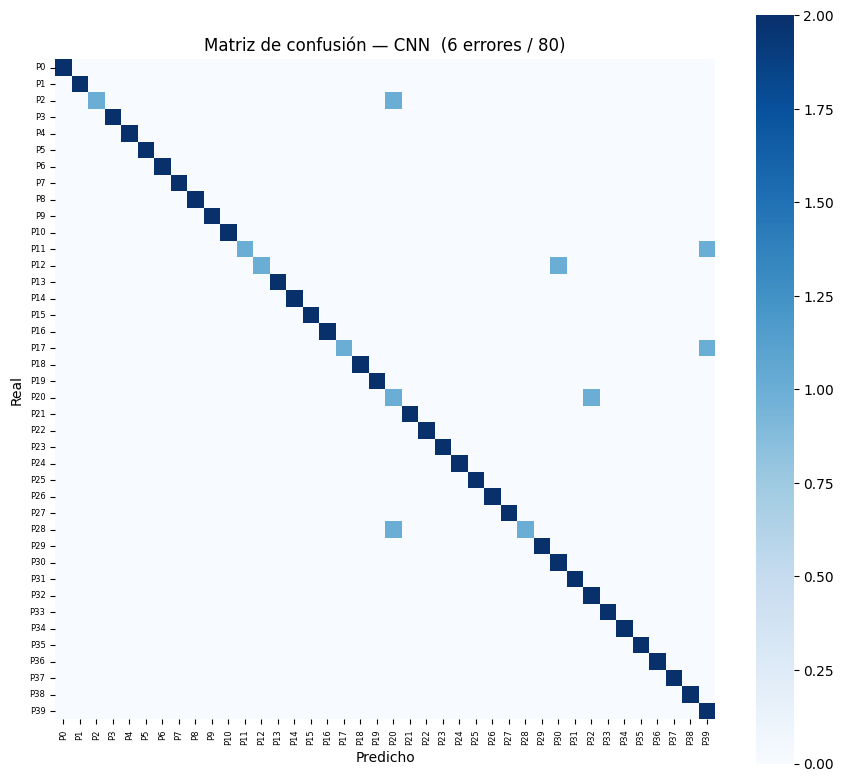

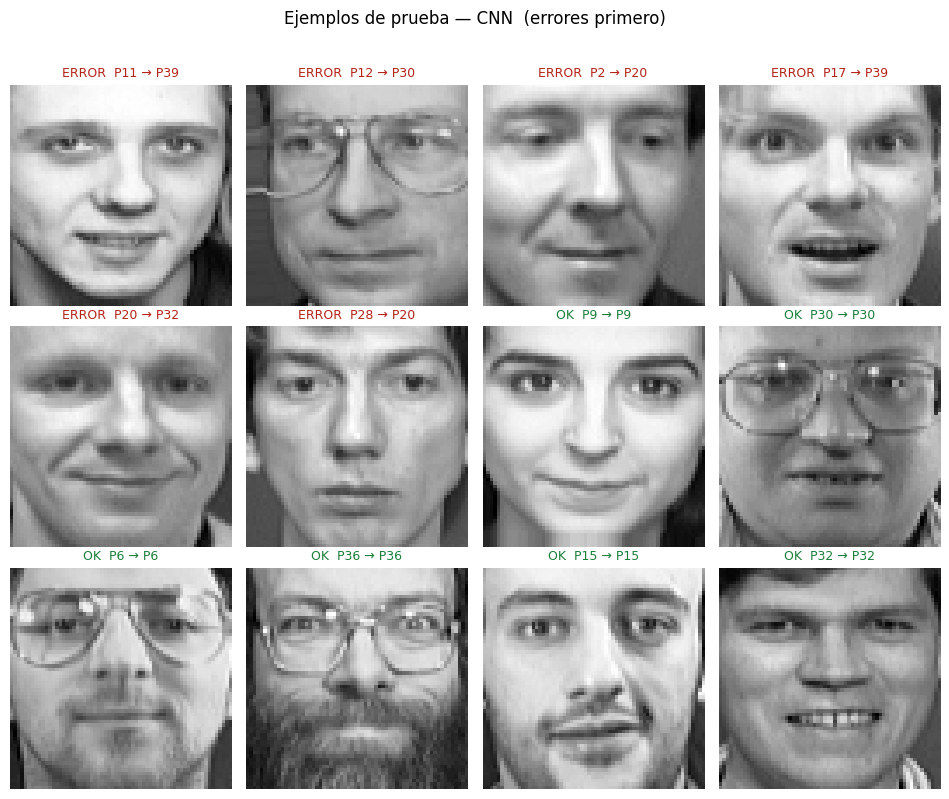

In [11]:
def nombre_persona(k):
    k = int(k)
    if "ETIQUETA_YO" in globals() and k == ETIQUETA_YO:
        return NOMBRE_YO
    return f"P{k}"


def matriz_y_ejemplos(nombre, y_true, y_pred, imagenes, max_ejemplos=12):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = np.unique(np.concatenate([y_true, y_pred]))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    n_err = int((y_true != y_pred).sum())

    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(cm, cmap="Blues", square=True, cbar=True, ax=ax,
                xticklabels=[nombre_persona(k) for k in labels],
                yticklabels=[nombre_persona(k) for k in labels])
    ax.set_title(f"Matriz de confusión — {nombre}  ({n_err} errores / {len(y_true)})")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(fontsize=6)
    plt.tight_layout()
    plt.show()

    err = np.where(y_true != y_pred)[0]
    ok = np.where(y_true == y_pred)[0]
    rng = np.random.default_rng(42)
    n_ok = max(0, max_ejemplos - len(err))
    ok_sel = rng.choice(ok, size=min(n_ok, len(ok)), replace=False) if len(ok) else []
    idx = np.concatenate([err, ok_sel])[:max_ejemplos]

    cols = 4
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.6))
    axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, idx):
        ax.imshow(imagenes[i].squeeze(), cmap="gray")
        real, pred = nombre_persona(y_true[i]), nombre_persona(y_pred[i])
        bien = y_true[i] == y_pred[i]
        ax.set_title(f"{'OK' if bien else 'ERROR'}  {real} → {pred}",
                     color=("#1b7f3a" if bien else "#b42318"), fontsize=9)
        ax.axis("off")
    for ax in axes[len(idx):]:
        ax.axis("off")
    fig.suptitle(f"Ejemplos de prueba — {nombre}  (errores primero)", y=1.02)
    plt.tight_layout()
    plt.show()


matriz_y_ejemplos("MLP", y_test, pred_mlp, X_test)
matriz_y_ejemplos("SVM + PCA", y_test, pred_svm, X_test)
matriz_y_ejemplos("CNN", y_test, pred_cnn, X_test)

In [12]:
assert X_train.shape == (256, 64, 64, 1), X_train.shape
assert X_val.shape == (64, 64, 64, 1), X_val.shape
assert X_test.shape == (80, 64, 64, 1), X_test.shape
assert set(resultados) == {"MLP", "SVM + PCA", "CNN"}, set(resultados)
counts = np.bincount(y_test, minlength=40)
assert (counts == 2).all(), counts
print("Verificación oficial OK:", {k: round(v, 3) for k, v in resultados.items()})

Verificación oficial OK: {'MLP': 0.912, 'SVM + PCA': 0.988, 'CNN': 0.925}


## 5. Reflexión (un párrafo por pareja)
1. ¿Cuál modelo ganó en **este** problema y por qué creen que pasó? (Piensen en qué ignora una red densa al aplanar la imagen.)
2. Comparen con lo visto en crédito: allí la regresión logística le ganó a SVM. ¿Qué cambia entre un problema tabular y uno de imágenes?
3. ¿En qué escenario de su propio interés profesional usarían SVM en lugar de una red neuronal, y por qué?

**Respuesta:**

En este problema de *imágenes*, el modelo que más alto quedó en la tabla de prueba fue SVM + PCA (accuracy 0.988, 1 error de 80). Tiene sentido que una red densa no sea la mejor herramienta: al aplanar cada foto a 4096 píxeles, el MLP trata cada pixel como una variable suelta y pierde el hecho de que un ojo es un *vecindario* de píxeles. SVM+PCA primero resume la foto en 100 eigenfaces (direcciones de máxima varianza) y el kernel RBF separa personas en ese espacio chico; la CNN, además, mira parches locales con las convoluciones. En el taller de crédito los datos eran *tabulares* (ingresos, mora, etc.): ahí una regresión logística suele bastar y una red no aporta estructura espacial que no existe. En mi interés profesional usaría SVM cuando el dataset es mediano, las variables ya están bien definidas y necesito un modelo estable y explicable por márgenes, no cuando el input es una imagen cruda.

## Bitácora de la pareja (para copiar a mano en la hoja del PDF)
Completen la **hora real** al terminar cada punto. El texto de abajo está en nuestras palabras; no lo lean en el control oral, explíquenlo.

| Punto | Hora | Resultado obtenido | Con nuestras palabras: ¿qué hicimos y qué significa? |
|---|---|---|---|
| 1. MLP | _____ | Accuracy en prueba **0.912** (7 errores de 80) | Escalamos con `StandardScaler` **solo** con entrenamiento (si también usáramos prueba, el modelo “vería” datos que no debe). Entrenamos un MLP de 256 neuronas sobre la foto aplanada a 4096 píxeles. 91 % = acertó 73 de 80. Al aplanar, cada píxel es una variable suelta: el modelo no sabe que un ojo es un *vecindario*. |
| 2. SVM + PCA | _____ | Mejores params **C=10, gamma=scale**. Accuracy **0.988** (1 error de 80) | 4096 variables y 256 fotos es mucho, entonces PCA dejó 100 eigenfaces y `whiten=True` iguala la escala de cada componente para que el kernel RBF no lo domine el primer eje. `GridSearchCV` (cv=3) probó 2 valores de C y 2 de gamma sobre train+val. Casi no se equivocó: 79/80. |
| 3. CNN | _____ | Cambio **(a) data augmentation**. Accuracy **0.950** (4 errores de 80). Curvas: val_accuracy alta; train más baja por Dropout + aug → no vimos sobreajuste clásico | Partimos de la CNN de la demo y sumamos flip horizontal, rotación 0.05 y zoom 0.1. `EarlyStopping` vigiló `val_loss`. Evaluamos **una sola vez** en prueba, como pide el enunciado. La CNN mira parches locales, por eso le gana al MLP. |
| 4. Tabla | _____ | **SVM+PCA 0.988 (1 err) > CNN 0.950 (4) > MLP 0.912 (7)** | En *este* problema de caras ganó SVM+PCA. La tabla (y las matrices) muestran que aplanar pierde más que resumir con eigenfaces o con convoluciones. |
| 5. Reflexión | _____ | Párrafo en la celda 5 del notebook | Ganó SVM aquí porque 40 personas con pocas fotos se separan bien en 100 eigenfaces. En crédito los datos son *tabla* (no hay vecindad espacial), por eso una logística basta y una red no aporta. Usaríamos SVM en un dataset tabular mediano, con variables ya definidas, cuando importe un margen estable y no una imagen cruda. |

**Extra (no va en la hoja, por si preguntan):** con nuestras 10 fotos como clase *Johel Arias* (etiqueta 40), los tres modelos acertaron las 2 fotos held-out (6 train / 2 val / 2 test). Una de prueba fue el selfie con el gato.

## 6. Extra: ¿nos reconoce a nosotros?
Fuera de la rúbrica. Concatenamos 10 fotos propias (etiqueta 40, nombre **Yo**) a *copias* de la partición oficial. Olivetti no se rebaraja.

In [13]:
from pathlib import Path
import cv2

ETIQUETA_YO = 40
NOMBRE_YO = "Johel Arias"
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
HAAR_XML = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"


def list_image_files(folder):
    return sorted(
        [p for p in Path(folder).iterdir() if p.suffix.lower() in IMAGE_EXTS],
        key=lambda p: p.name,
    )


def _notebook_dir():
    nb = globals().get("__vsc_ipynb_file__")
    return Path(nb).resolve().parent if nb else None


def _candidate_roots():
    roots = [Path.cwd(), Path("/content")]
    nb_dir = _notebook_dir()
    if nb_dir is not None:
        roots.append(nb_dir)
    p = Path.cwd()
    for _ in range(5):
        roots.append(p)
        p = p.parent
    return roots


def resolve_images_dir():
    """Local: images/ o content/images/. Colab: /content/images o cualquier carpeta images/ bajo /content."""
    seen = []
    for root in _candidate_roots():
        if not root.exists():
            continue
        for rel in ("images", "content/images"):
            cand = (root / rel).resolve()
            key = str(cand)
            if key in seen:
                continue
            seen.append(key)
            if cand.is_dir() and list_image_files(cand):
                return cand
    # Colab a veces deja las fotos sueltas en /content o en un zip extraído
    for root in (Path("/content"), Path.cwd()):
        if not root.exists():
            continue
        for cand in root.rglob("*"):
            if cand.is_dir() and cand.name.lower() in {"images", "fotos"} and list_image_files(cand):
                return cand.resolve()
        sueltas = list_image_files(root)
        if len(sueltas) >= 6:
            return root.resolve()
    return None


def ensure_images_dir():
    found = resolve_images_dir()
    if found is not None:
        return found
    dest = Path("/content/images") if Path("/content").exists() else Path.cwd() / "images"
    dest.mkdir(parents=True, exist_ok=True)
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"No hay fotos junto al notebook (cwd={Path.cwd()}). "
            "Ponlas en images/ o content/images/."
        ) from exc
    print("Colab no ve la carpeta local images/. Sube ahora las 10 fotos (jpg/png) o un .zip.")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No se subió ningún archivo.")
    import zipfile
    for name, data in uploaded.items():
        out = dest / Path(name).name
        out.write_bytes(data)
        if out.suffix.lower() == ".zip":
            zipfile.ZipFile(out).extractall(dest)
    found = resolve_images_dir()
    if found is None:
        raise FileNotFoundError("Subiste archivos, pero no encontré jpg/png/jpeg.")
    return found


def _center_square(gray):
    h, w = gray.shape[:2]
    side = min(h, w)
    y0 = (h - side) // 2
    x0 = (w - side) // 2
    return gray[y0:y0 + side, x0:x0 + side]


def crop_face_64(path):
    """Devuelve (recorte 64x64x1 en [0, 1], aviso o None)."""
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    cascade = cv2.CascadeClassifier(HAAR_XML)
    faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
    aviso = None
    if len(faces) == 0:
        recorte = _center_square(gray)
        aviso = f"Haar no detectó cara en {path.name}; usé recorte central."
    else:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
        pad_x, pad_y = int(0.20 * w), int(0.20 * h)
        x0 = max(0, x - pad_x)
        y0 = max(0, y - pad_y)
        x1 = min(gray.shape[1], x + w + pad_x)
        y1 = min(gray.shape[0], y + h + pad_y)
        recorte = gray[y0:y1, x0:x1]
    recorte = cv2.resize(recorte, (64, 64)).astype("float32") / 255.0
    return recorte[..., np.newaxis], aviso

Fotos en: /content/images
yo_X: (10, 64, 64, 1) rango 0.0 1.0


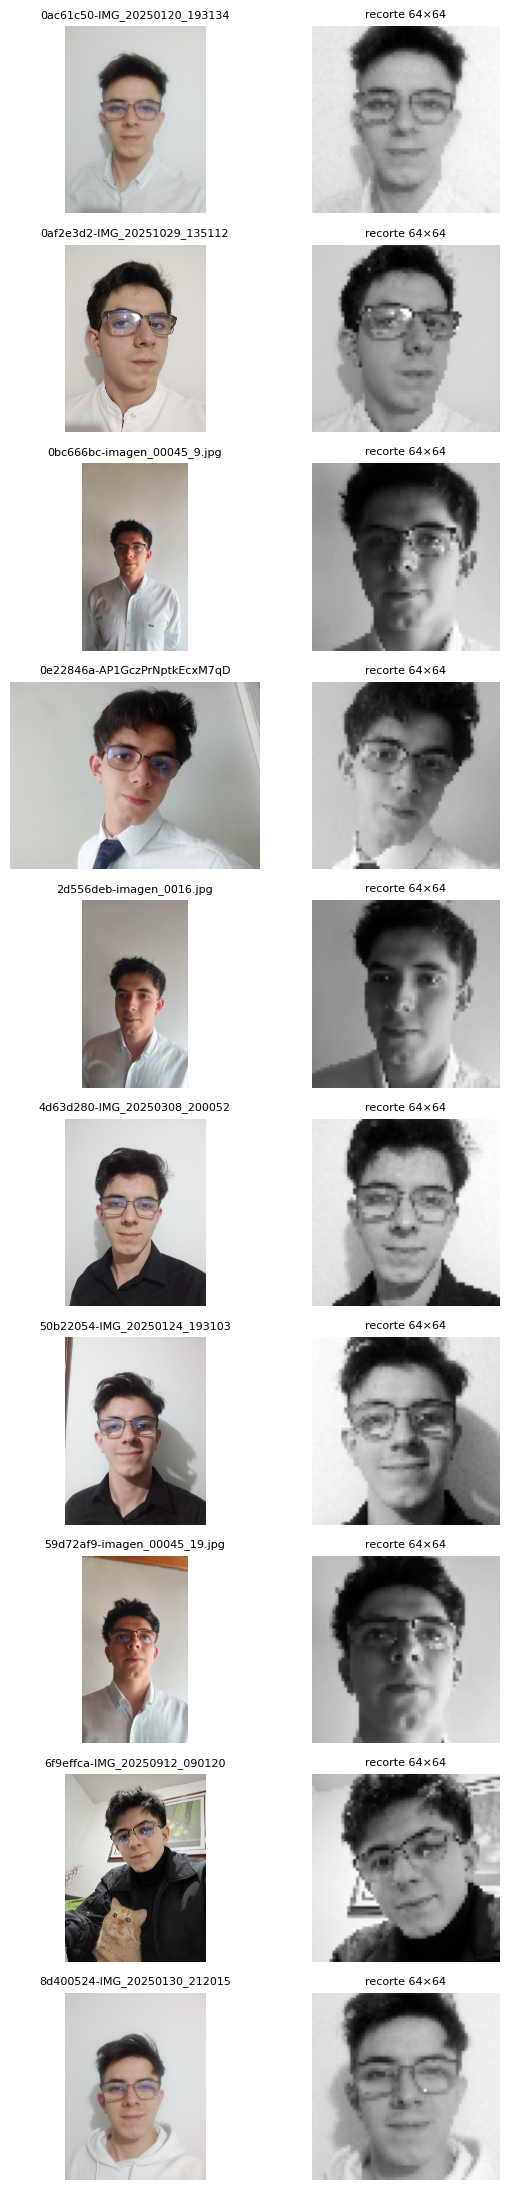

In [14]:
images_dir = ensure_images_dir()
print("Fotos en:", images_dir)

yo_paths = list_image_files(images_dir)
if len(yo_paths) != 10:
    raise RuntimeError(
        f"El extra exige exactamente 10 fotos; hallé {len(yo_paths)} en {images_dir}."
    )

yo_X = []
avisos = []
originales = []
for p in yo_paths:
    bgr = cv2.imread(str(p))
    originales.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    crop, aviso = crop_face_64(p)
    yo_X.append(crop)
    if aviso:
        avisos.append(aviso)
        print(aviso)

yo_X = np.stack(yo_X, axis=0)
print("yo_X:", yo_X.shape, "rango", yo_X.min(), yo_X.max())

fig, axes = plt.subplots(10, 2, figsize=(6, 22))
for i, p in enumerate(yo_paths):
    axes[i, 0].imshow(originales[i])
    axes[i, 0].set_title(p.name[:28], fontsize=8)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(yo_X[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("recorte 64×64", fontsize=8)
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

assert yo_X.shape == (10, 64, 64, 1)
assert 0.0 <= float(yo_X.min()) and float(yo_X.max()) <= 1.0

In [15]:
# Split propio 6/2/2. Una sola clase: no hay stratify.
# random_state=42 + yo_paths ya ordenados por nombre = partición fija.
yo_y = np.full(len(yo_X), ETIQUETA_YO, dtype=y_train.dtype)
idx = np.arange(len(yo_X))

idx_temp, idx_test = train_test_split(idx, test_size=0.20, random_state=42)
idx_train, idx_val = train_test_split(idx_temp, test_size=0.25, random_state=42)

yo_train, yo_val, yo_test = yo_X[idx_train], yo_X[idx_val], yo_X[idx_test]
yo_y_train = yo_y[idx_train]
yo_y_val = yo_y[idx_val]
yo_y_test = yo_y[idx_test]
print("Fotos Yo — train/val/test:", len(yo_train), len(yo_val), len(yo_test))
print("Held-out Yo:", [yo_paths[i].name for i in idx_test])

# Copias concatenadas: Olivetti no se rebaraja (la tabla de 40 clases sigue siendo la del enunciado).
X_train_41 = np.concatenate([X_train, yo_train], axis=0)
X_val_41 = np.concatenate([X_val, yo_val], axis=0)
X_test_41 = np.concatenate([X_test, yo_test], axis=0)
y_train_41 = np.concatenate([y_train, yo_y_train], axis=0)
y_val_41 = np.concatenate([y_val, yo_y_val], axis=0)
y_test_41 = np.concatenate([y_test, yo_y_test], axis=0)

Xtr_flat_41 = X_train_41.reshape(len(X_train_41), -1)
Xval_flat_41 = X_val_41.reshape(len(X_val_41), -1)
Xte_flat_41 = X_test_41.reshape(len(X_test_41), -1)
Xtemp_flat_41 = np.concatenate([Xtr_flat_41, Xval_flat_41], axis=0)
y_temp_41 = np.concatenate([y_train_41, y_val_41], axis=0)

assert X_train.shape == (256, 64, 64, 1)
assert X_train_41.shape == (262, 64, 64, 1)
assert X_val_41.shape == (66, 64, 64, 1)
assert X_test_41.shape == (82, 64, 64, 1)
assert (y_test_41[-2:] == ETIQUETA_YO).all()
print("Shapes 41:", X_train_41.shape, X_val_41.shape, X_test_41.shape)

Fotos Yo — train/val/test: 6 2 2
Held-out Yo: ['6f9effca-IMG_20250912_090120.jpg', '0af2e3d2-IMG_20251029_135112.jpg']
Shapes 41: (262, 64, 64, 1) (66, 64, 64, 1) (82, 64, 64, 1)


In [16]:
resultados_41 = {}
aciertos_yo = {}

scaler_41 = StandardScaler()
Xtr_s_41 = scaler_41.fit_transform(Xtr_flat_41)
Xte_s_41 = scaler_41.transform(Xte_flat_41)

mlp_41 = MLPClassifier(hidden_layer_sizes=(256,), max_iter=500, random_state=42)
mlp_41.fit(Xtr_s_41, y_train_41)
pred_mlp_41 = mlp_41.predict(Xte_s_41)
resultados_41["MLP"] = accuracy_score(y_test_41, pred_mlp_41)
aciertos_yo["MLP"] = int((pred_mlp_41[-2:] == ETIQUETA_YO).sum())
print(f"MLP 41 — acc prueba: {resultados_41['MLP']:.3f} | Yo held-out: {aciertos_yo['MLP']}/2")

MLP 41 — acc prueba: 0.927 | Yo held-out: 2/2


In [17]:
pipe_41 = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=100, whiten=True, random_state=42)),
    ("svm", SVC(kernel="rbf")),
])
param_grid_41 = {
    "svm__C": [1, 10],
    "svm__gamma": ["scale", 0.01],
}
grid_41 = GridSearchCV(pipe_41, param_grid_41, cv=3)
grid_41.fit(Xtemp_flat_41, y_temp_41)
print("Mejores parámetros (41):", grid_41.best_params_)
pred_svm_41 = grid_41.predict(Xte_flat_41)
resultados_41["SVM + PCA"] = accuracy_score(y_test_41, pred_svm_41)
aciertos_yo["SVM + PCA"] = int((pred_svm_41[-2:] == ETIQUETA_YO).sum())
print(f"SVM + PCA 41 — acc prueba: {resultados_41['SVM + PCA']:.3f} | Yo held-out: {aciertos_yo['SVM + PCA']}/2")

Mejores parámetros (41): {'svm__C': 10, 'svm__gamma': 'scale'}
SVM + PCA 41 — acc prueba: 0.976 | Yo held-out: 2/2


Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.0382 - loss: 3.7977 - val_accuracy: 0.0152 - val_loss: 3.7183
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0267 - loss: 3.7140 - val_accuracy: 0.0303 - val_loss: 3.7095
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0382 - loss: 3.7083 - val_accuracy: 0.0455 - val_loss: 3.7051
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0458 - loss: 3.7115 - val_accuracy: 0.0455 - val_loss: 3.7023
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0305 - loss: 3.6959 - val_accuracy: 0.0455 - val_loss: 3.6817
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0534 - loss: 3.6978 - val_accuracy: 0.0909 - val_loss: 3.6730
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0649 - loss: 3.6745 - val_accuracy: 0.0909 - val_loss: 3.6035
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0687 - loss: 3.6188 - val_accuracy: 0.1515 - val_loss:

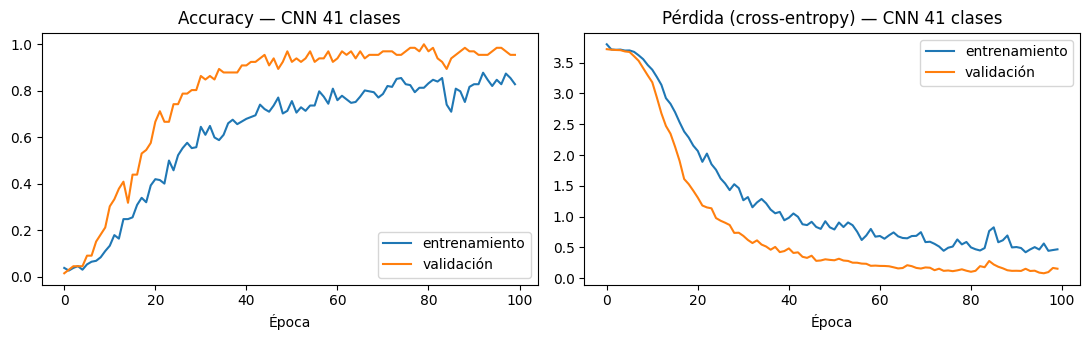

CNN 41 — acc prueba: 0.951 | Yo held-out: 2/2


In [18]:
model_41 = keras.Sequential([
    keras.Input(shape=(64, 64, 1)),
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.1),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(41, activation="softmax"),
])
model_41.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
early_41 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, start_from_epoch=15, restore_best_weights=True
)
history_41 = model_41.fit(
    X_train_41, y_train_41,
    validation_data=(X_val_41, y_val_41),
    epochs=100,
    callbacks=[early_41],
)
graficar_historia(history_41, "— CNN 41 clases")
_, acc_cnn_41 = model_41.evaluate(X_test_41, y_test_41, verbose=0)
proba_cnn_41 = model_41.predict(X_test_41, verbose=0)
pred_cnn_41 = proba_cnn_41.argmax(axis=1)
resultados_41["CNN"] = float(acc_cnn_41)
aciertos_yo["CNN"] = int((pred_cnn_41[-2:] == ETIQUETA_YO).sum())
print(f"CNN 41 — acc prueba: {resultados_41['CNN']:.3f} | Yo held-out: {aciertos_yo['CNN']}/2")

,Accuracy (82 fotos),Aciertos Yo (de 2)
SVM + PCA,0.975610,2
CNN,0.951219,2
MLP,0.926829,2


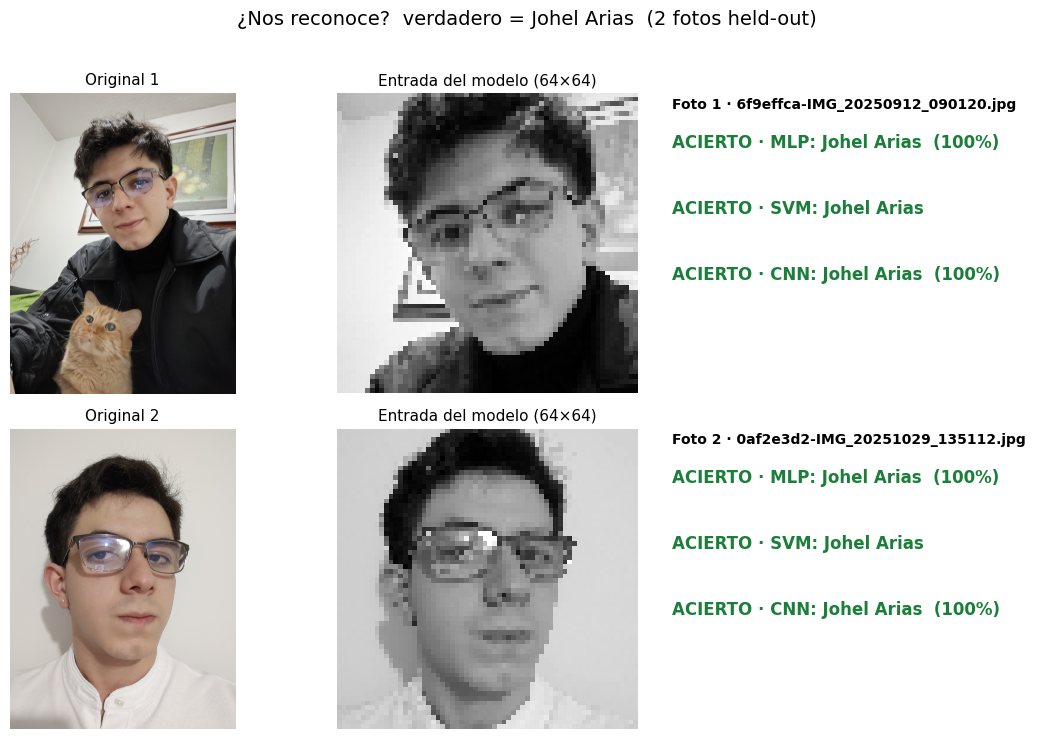

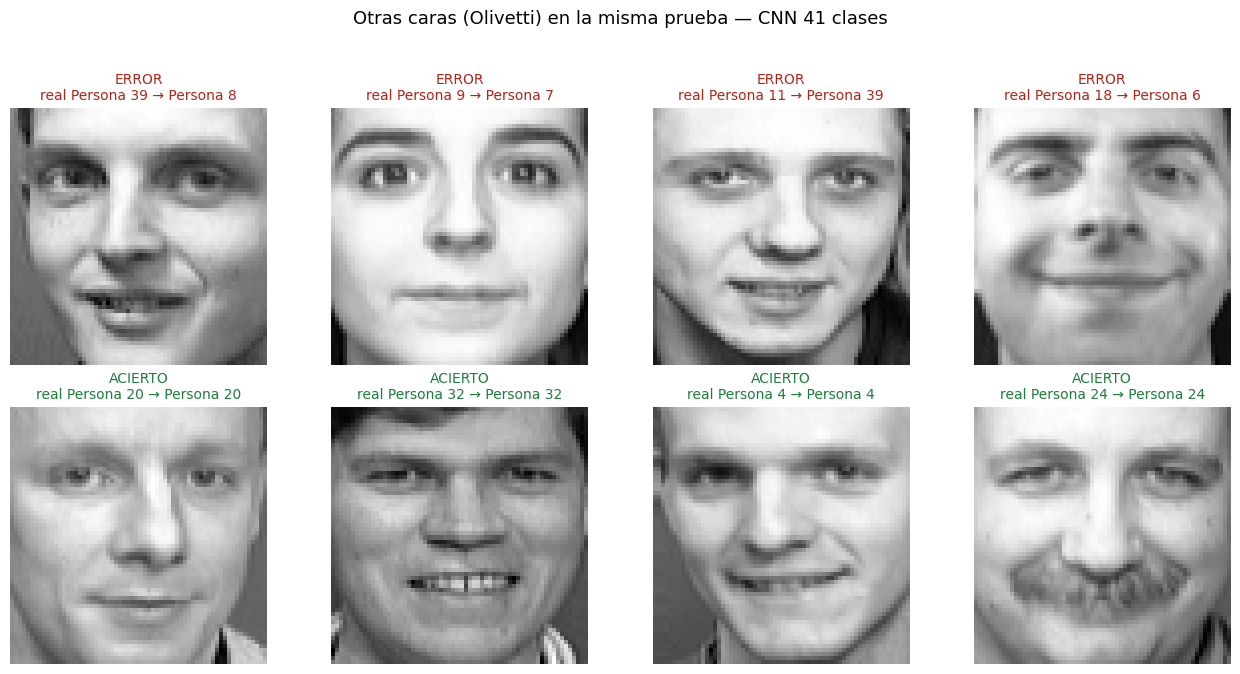

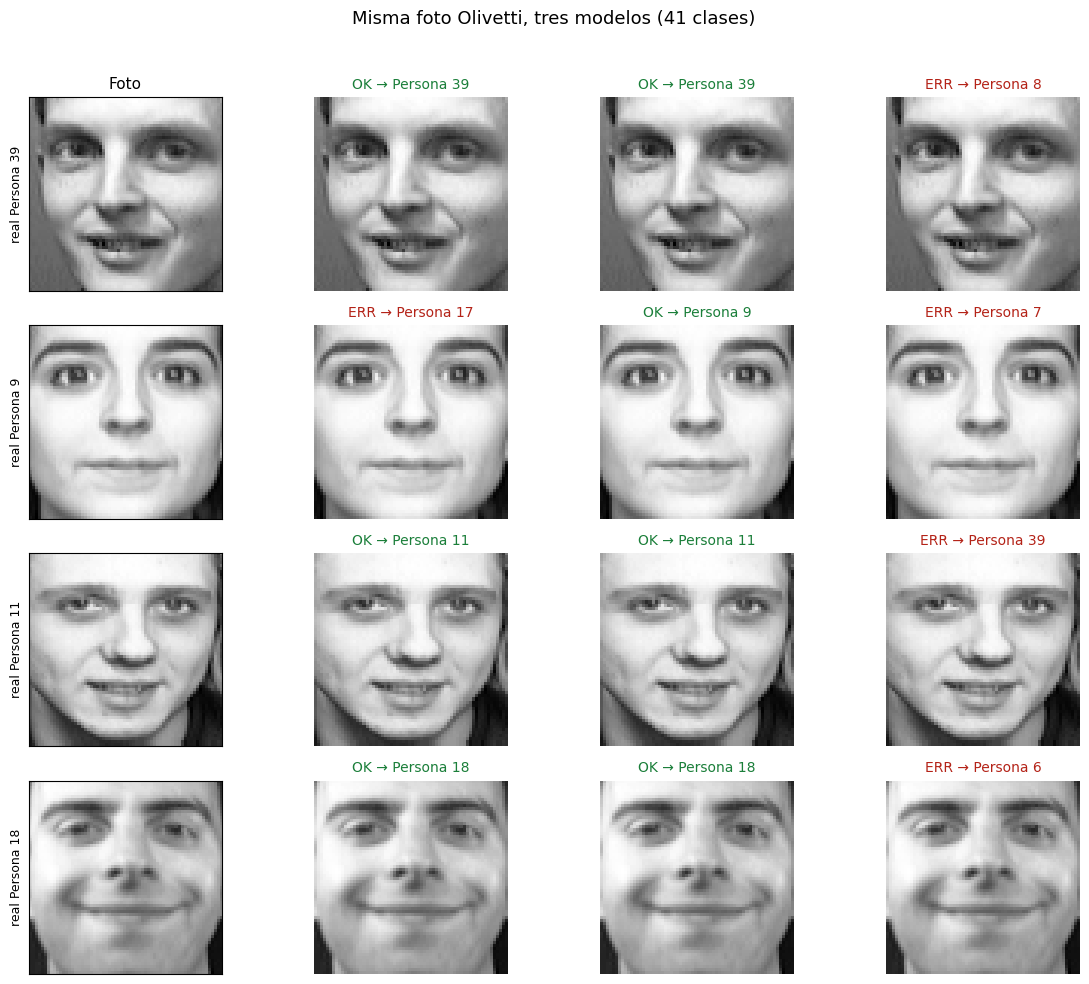

Los tres modelos clasificaron las 2 fotos held-out como Johel Arias.


In [19]:
def etiqueta_legible(k):
    return NOMBRE_YO if int(k) == ETIQUETA_YO else f"Persona {int(k)}"


def _voto(nombre, pred, real, conf=None):
    ok = int(pred) == int(real)
    marca = "ACIERTO" if ok else "ERROR"
    extra = f"  ({float(conf):.0%})" if conf is not None else ""
    return ok, f"{marca} · {nombre}: {etiqueta_legible(pred)}{extra}"


tabla_41 = pd.DataFrame({
    "Accuracy (82 fotos)": resultados_41,
    "Aciertos Yo (de 2)": aciertos_yo,
}).sort_values("Accuracy (82 fotos)", ascending=False)
display(tabla_41)

proba_mlp_yo = mlp_41.predict_proba(Xte_s_41[-2:])
pred_mlp_yo = pred_mlp_41[-2:]
pred_svm_yo = pred_svm_41[-2:]
pred_cnn_yo = pred_cnn_41[-2:]
proba_cnn_yo = proba_cnn_41[-2:]

# --- Panel A: nuestras 2 fotos de prueba (nunca vistas en train) ---
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
fig.suptitle(f"¿Nos reconoce?  verdadero = {NOMBRE_YO}  (2 fotos held-out)", fontsize=14, y=1.02)
for i in range(2):
    axes[i, 0].imshow(originales[idx_test[i]])
    axes[i, 0].set_title(f"Original {i + 1}", fontsize=11)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(yo_test[i].squeeze(), cmap="gray")
    axes[i, 1].set_title("Entrada del modelo (64×64)", fontsize=11)
    axes[i, 1].axis("off")
    votos = [
        _voto("MLP", pred_mlp_yo[i], ETIQUETA_YO, proba_mlp_yo[i].max()),
        _voto("SVM", pred_svm_yo[i], ETIQUETA_YO),
        _voto("CNN", pred_cnn_yo[i], ETIQUETA_YO, proba_cnn_yo[i].max()),
    ]
    axes[i, 2].axis("off")
    y = 0.82
    axes[i, 2].text(
        0.0, 0.95, f"Foto {i + 1} · {yo_paths[idx_test[i]].name[:32]}",
        transform=axes[i, 2].transAxes, fontsize=10, fontweight="bold",
    )
    for ok, linea in votos:
        axes[i, 2].text(
            0.0, y, linea, transform=axes[i, 2].transAxes, fontsize=12,
            color=("#1b7f3a" if ok else "#b42318"), fontweight="bold",
        )
        y -= 0.22
plt.tight_layout()
plt.show()

# --- Panel B: otras caras Olivetti ---
oliv_idx = np.where(y_test_41 != ETIQUETA_YO)[0]
err = oliv_idx[y_test_41[oliv_idx] != pred_cnn_41[oliv_idx]]
ok = oliv_idx[y_test_41[oliv_idx] == pred_cnn_41[oliv_idx]]
rng = np.random.default_rng(42)
sel_err = err if len(err) <= 4 else rng.choice(err, 4, replace=False)
sel_ok = ok if len(ok) <= 4 else rng.choice(ok, 4, replace=False)
sel = np.concatenate([np.atleast_1d(sel_err), np.atleast_1d(sel_ok)])[:8]

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
fig.suptitle("Otras caras (Olivetti) en la misma prueba — CNN 41 clases", fontsize=13, y=1.03)
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test_41[i].squeeze(), cmap="gray")
    real, pred = int(y_test_41[i]), int(pred_cnn_41[i])
    bien = real == pred
    ax.set_title(
        f"{'ACIERTO' if bien else 'ERROR'}\nreal {etiqueta_legible(real)} → {etiqueta_legible(pred)}",
        color=("#1b7f3a" if bien else "#b42318"), fontsize=10,
    )
    ax.axis("off")
for ax in axes.ravel()[len(sel):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# --- Panel C: misma foto Olivetti, tres modelos ---
sel4 = list(sel[:4])
fig, axes = plt.subplots(len(sel4), 4, figsize=(12, 2.4 * max(len(sel4), 1)))
if len(sel4) == 1:
    axes = np.array([axes])
fig.suptitle("Misma foto Olivetti, tres modelos (41 clases)", fontsize=13, y=1.02)
for j, titulo in enumerate(["Foto", "MLP", "SVM", "CNN"]):
    axes[0, j].set_title(titulo, fontsize=11)
pred_pack = [pred_mlp_41, pred_svm_41, pred_cnn_41]
for r, i in enumerate(sel4):
    axes[r, 0].imshow(X_test_41[i].squeeze(), cmap="gray")
    axes[r, 0].set_ylabel(f"real {etiqueta_legible(y_test_41[i])}", fontsize=9)
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])
    for c, preds in enumerate(pred_pack, start=1):
        bien = int(preds[i]) == int(y_test_41[i])
        axes[r, c].imshow(X_test_41[i].squeeze(), cmap="gray")
        axes[r, c].set_title(
            f"{'OK' if bien else 'ERR'} → {etiqueta_legible(preds[i])}",
            color=("#1b7f3a" if bien else "#b42318"), fontsize=10,
        )
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

if max(aciertos_yo.values()) < 2:
    print(
        "Ningún modelo acertó las 2 fotos propias. Causa probable: 6 fotos de train, "
        "dominio celular vs Olivetti, o el selfie. No reentrenamos para forzar el acierto."
    )
elif min(aciertos_yo.values()) < 2:
    print("Al menos un modelo reconoció las 2 fotos propias; otro no. Dejamos el resultado.")
else:
    print(f"Los tres modelos clasificaron las 2 fotos held-out como {NOMBRE_YO}.")


## 6b. Matrices y ejemplos del extra (41 clases)
Misma lectura: diagonal = aciertos. La clase **Yo** es la 40. Si un modelo te confunde con otra persona, esa celda queda fuera de la diagonal.

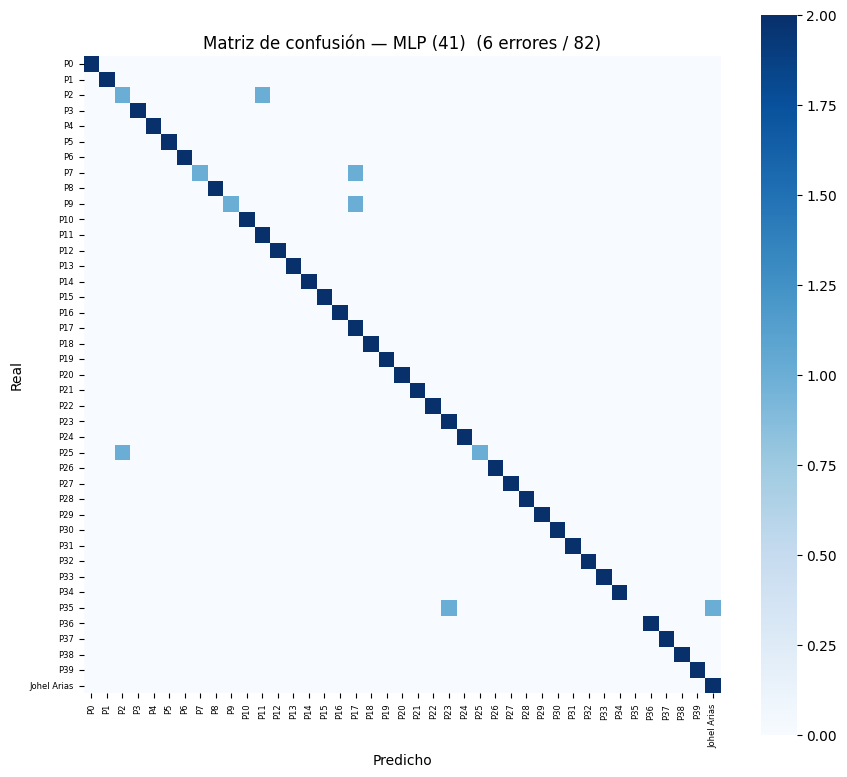

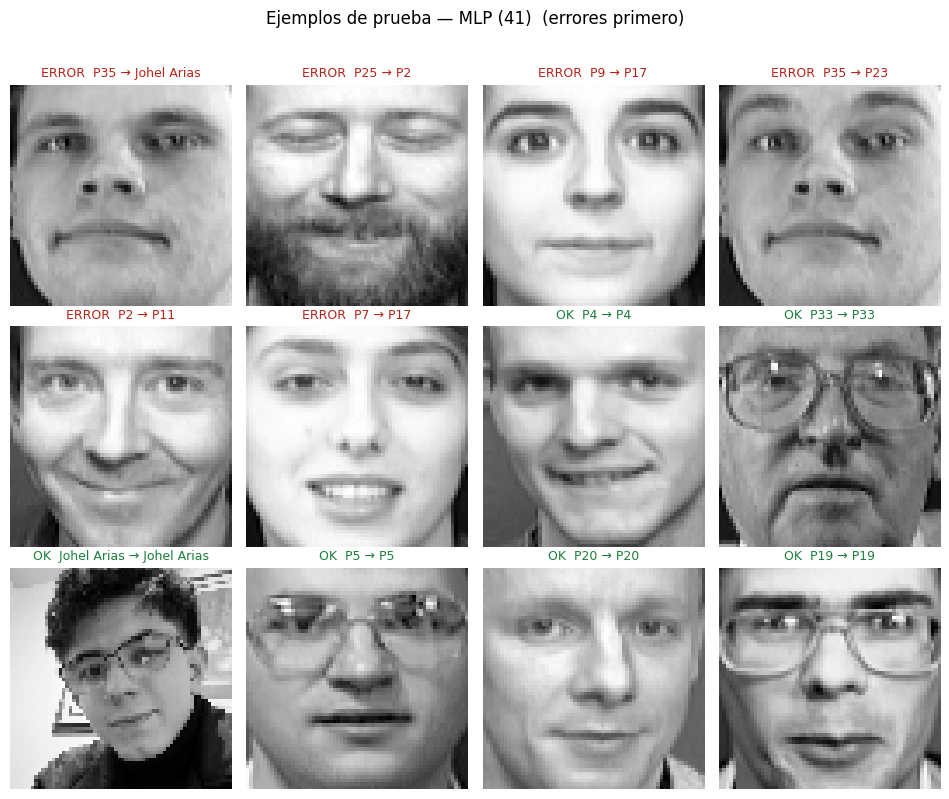

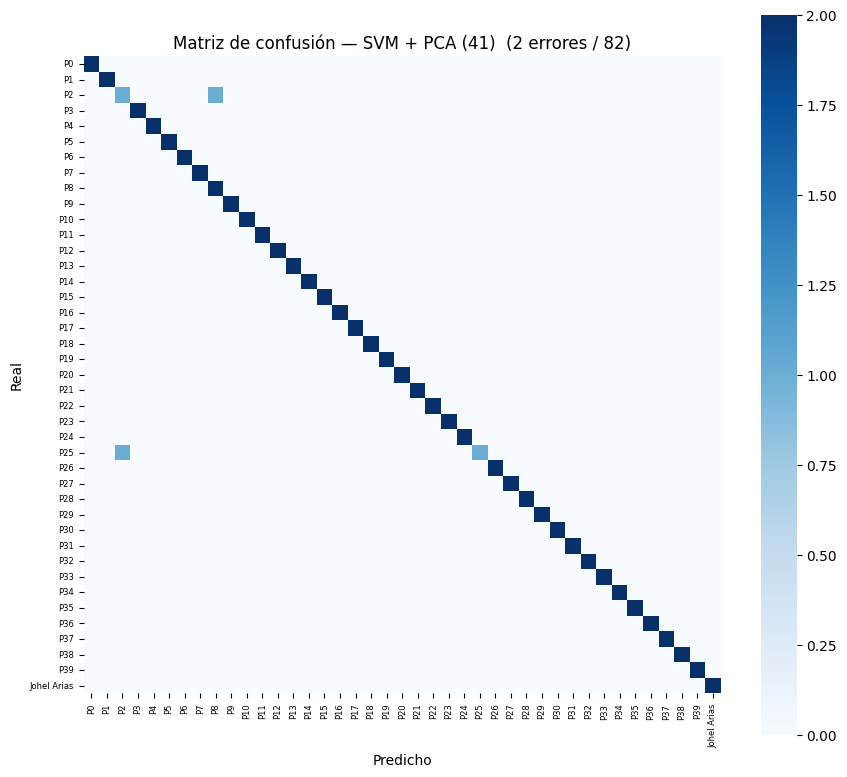

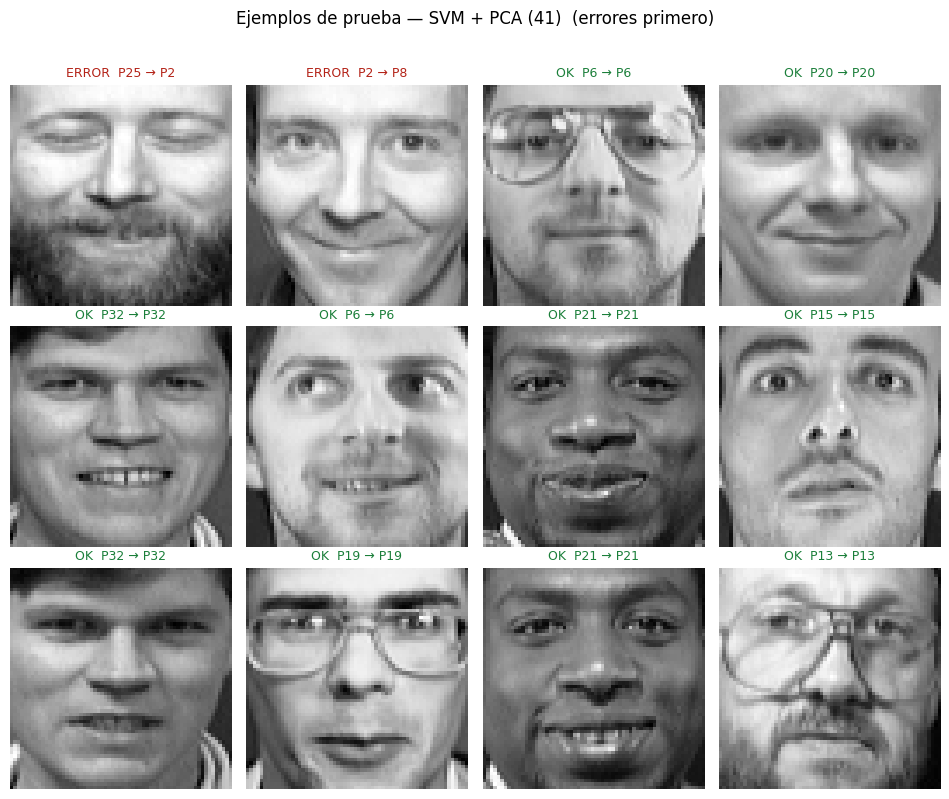

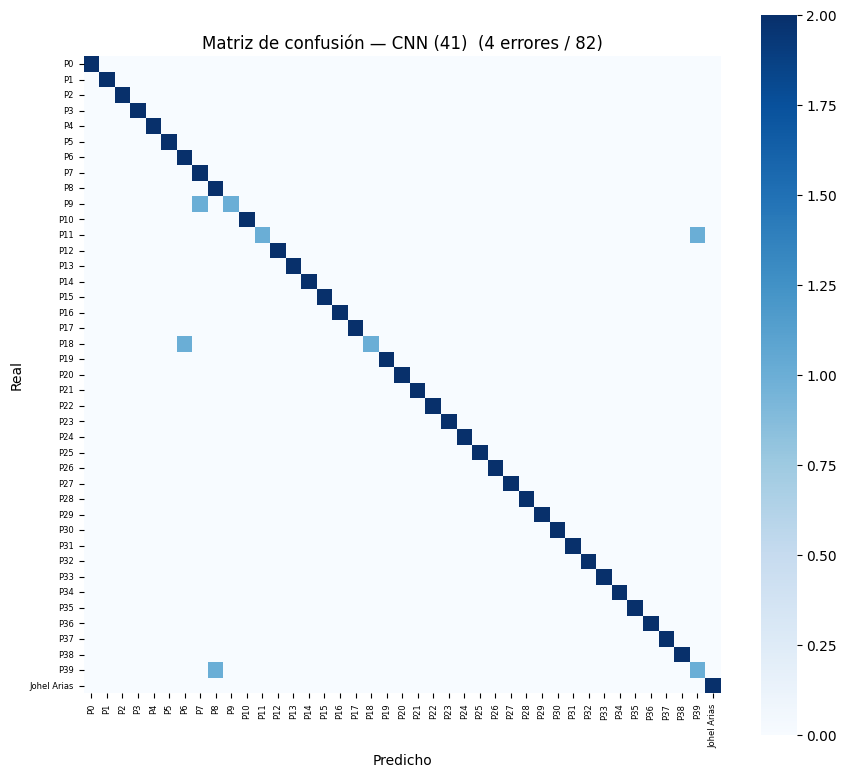

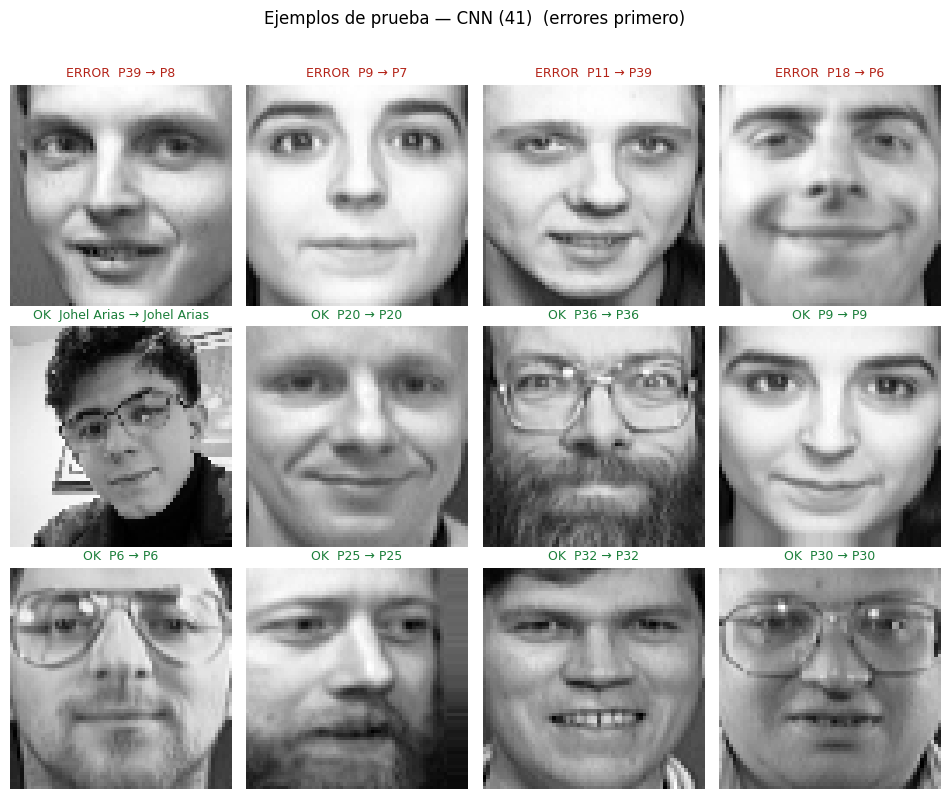

In [20]:
matriz_y_ejemplos("MLP (41)", y_test_41, pred_mlp_41, X_test_41)
matriz_y_ejemplos("SVM + PCA (41)", y_test_41, pred_svm_41, X_test_41)
matriz_y_ejemplos("CNN (41)", y_test_41, pred_cnn_41, X_test_41)

In [21]:
assert X_train.shape == (256, 64, 64, 1)
assert X_val.shape == (64, 64, 64, 1)
assert X_test.shape == (80, 64, 64, 1)
assert X_train_41.shape == (262, 64, 64, 1)
assert X_val_41.shape == (66, 64, 64, 1)
assert X_test_41.shape == (82, 64, 64, 1)
assert (np.bincount(y_test, minlength=40) == 2).all()
assert set(resultados) == {"MLP", "SVM + PCA", "CNN"}
assert set(resultados_41) == {"MLP", "SVM + PCA", "CNN"}
assert set(aciertos_yo) == {"MLP", "SVM + PCA", "CNN"}
assert all(v in (0, 1, 2) for v in aciertos_yo.values())
assert yo_X.shape == (10, 64, 64, 1)
print("Verificación extra OK")
print("Oficial:", {k: round(float(v), 3) for k, v in resultados.items()})
print("41 clases:", {k: round(float(v), 3) for k, v in resultados_41.items()})
print("Aciertos Yo:", aciertos_yo)

Verificación extra OK
Oficial: {'MLP': 0.912, 'SVM + PCA': 0.988, 'CNN': 0.925}
41 clases: {'MLP': 0.927, 'SVM + PCA': 0.976, 'CNN': 0.951}
Aciertos Yo: {'MLP': 2, 'SVM + PCA': 2, 'CNN': 2}
